# Example of the aitlas toolbox in the context of image segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import OpenCanopyDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 68


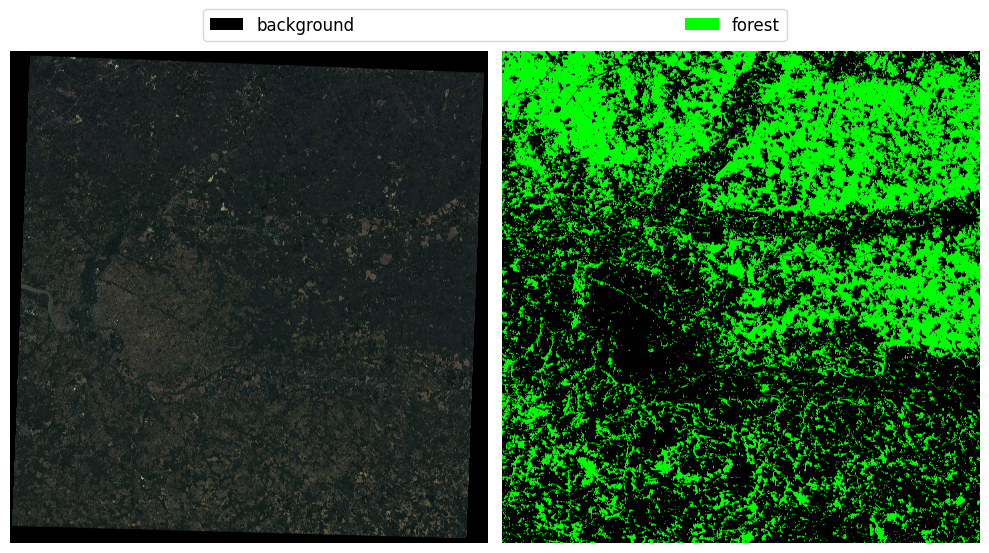

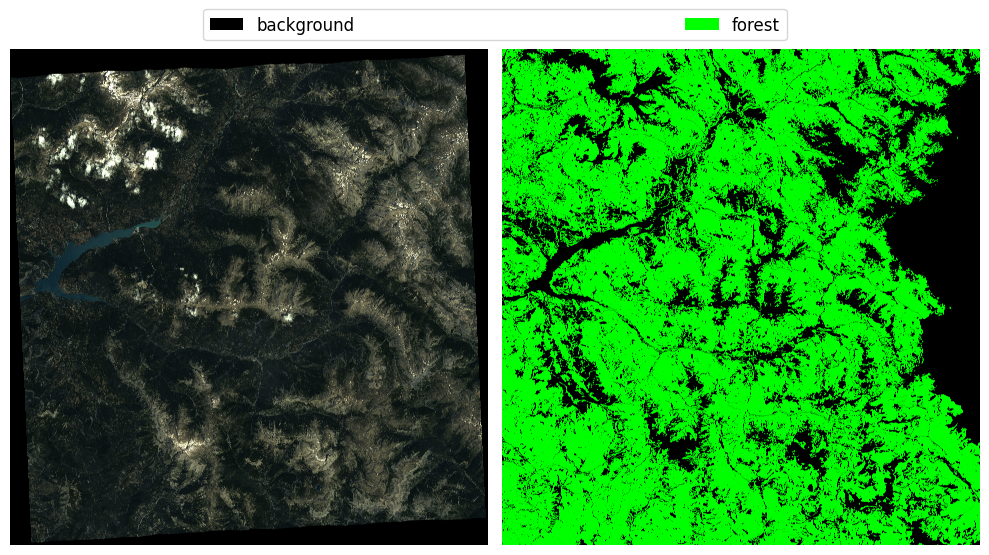

In [8]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height",
    "selection": "rgb"
}
dataset = OpenCanopyDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);

In [5]:
dataset.data_distribution_table()

,Number of pixels
background,5.244891e+10
forest,3.440548e+10


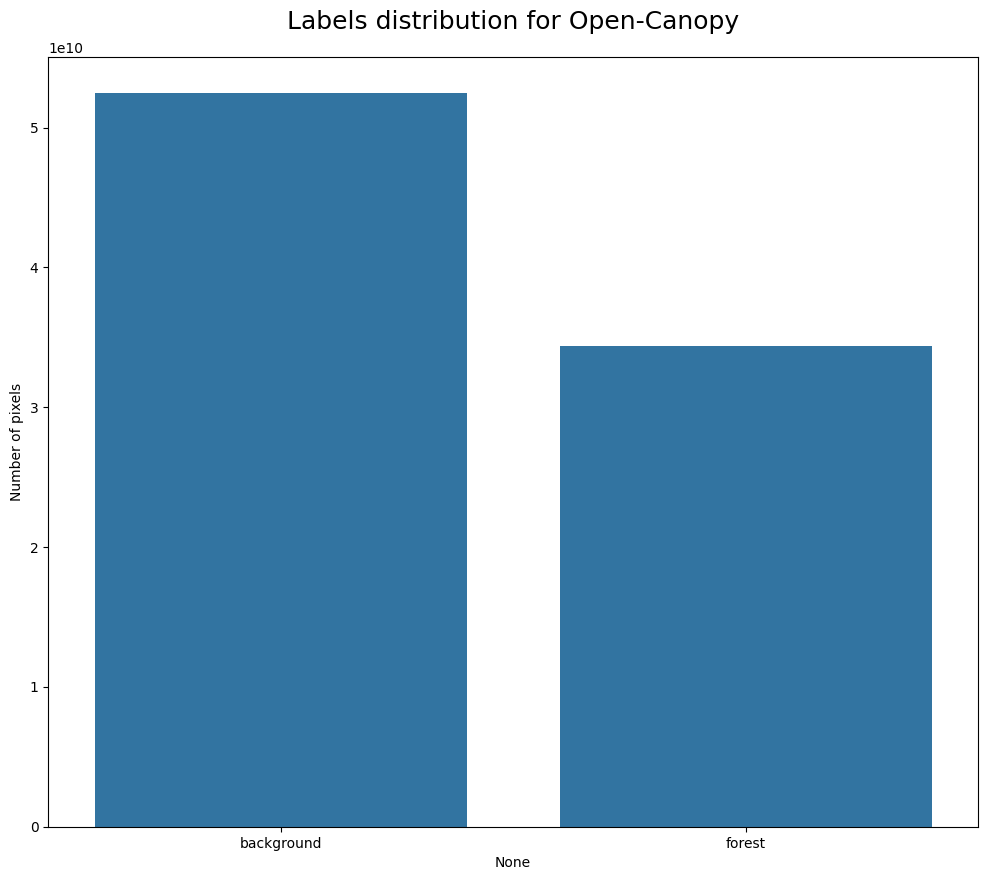

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height",
    "csv_file": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height/geometries.geojson",
    "selection": "rgb",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = OpenCanopyDataset(train_dataset_config)
len(train_dataset)

68

## Create the model

In [4]:
epochs = 1
model_directory = "/home/dragik/data/FAIR_EO/open_canopy"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-05-27 06:42:57,213 INFO Starting training.
training: 100%|██████████| 17/17 [14:00:07<00:00, 2965.14s/it]   
2026-05-27 20:43:04,697 INFO epoch: 1, time: 50407, loss:  0.45223
testing on train set: 100%|██████████| 17/17 [15:26:58<00:00, 3271.70s/it]  
2026-05-28 12:10:05,221 INFO IOU:0.16105348559676605, IOU mean:0.19194325683843094, IOU per Class:[0.29627423 0.08761229]
2026-05-28 12:10:07,291 INFO Train loss: [0.45840102083542766]
2026-05-28 12:10:07,295 INFO Validation loss: []
2026-05-28 12:10:07,295 INFO Train time per epochs: [50407]
2026-05-28 12:10:07,297 INFO Finished training. training time: 50407


## Evaluate the model

In [6]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height",
    "csv_file": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height/geometries.geojson",
    "selection": "rgb",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = OpenCanopyDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

67


2026-05-29 07:39:21,067 INFO Loading checkpoint /home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar
2026-05-29 07:39:21,676 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar at epoch 2
testing on test set: 100%|██████████| 17/17 [11:49:41<00:00, 2504.81s/it]  


[{'IOU': 0.16185559716575693,
  'IOU mean': 0.1928665648063557,
  'IOU per Class': array([0.29900406, 0.08672907])}]

## Predictions

2026-06-01 06:45:23,990 INFO Loading checkpoint /home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar
2026-06-01 06:45:24,625 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar at epoch 2


52


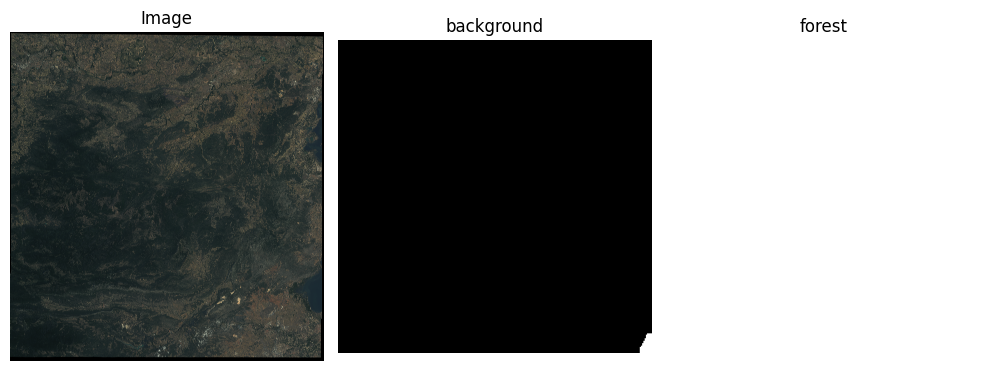

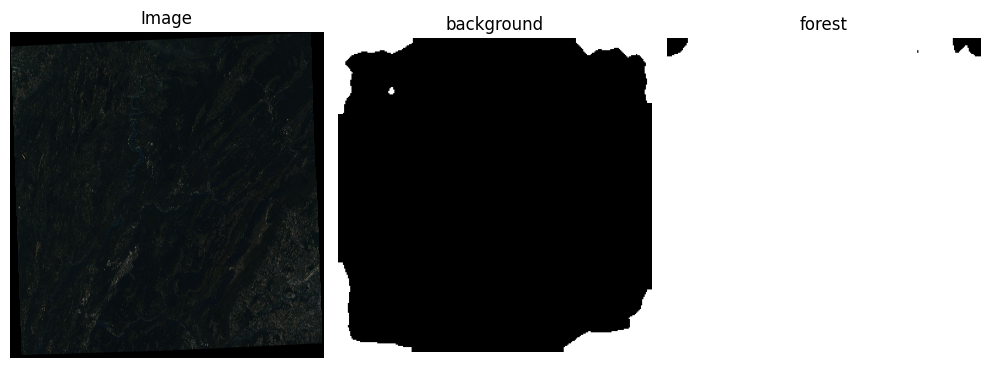

In [5]:
model_path = "/home/dragik/data/FAIR_EO/open_canopy/checkpoint.pth.tar"
labels = ["background","forest"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height",
    "csv_file": "/home/dragik/data/FAIR_EO/open_canopy/canopy_height/geometries.geojson",
    "selection": "rgb",
    "mode": "test"
}
test_dataset = OpenCanopyDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)